# Statistics for Machine Learning in Finance

**A comprehensive, hands-on notebook** | Simulated financial data | Reproducible experiments | Statistical intuition → Python → ML decisions

### Learning approach
For every topic: **what it measures → why it matters → assumptions → financial application → visualization → Python experiment → interview explanation**. All returns, trading signals, portfolios, customers and market states are **synthetic**; nothing here is historical investment performance.

**Suggested preparation:** Work through Parts I–III first, then Part IV for ML validation, and Part V for advanced finance/time-series interviews. Change the random seed, sample size, volatility and effect sizes and observe which conclusions change.

**Prerequisites:** Python basics, pandas, NumPy. The notebook uses NumPy, pandas, SciPy, Matplotlib and scikit-learn; optional statsmodels sections degrade gracefully if unavailable.

> Educational statistical simulations, not trading recommendations. P-values and estimated model performance can be fragile under serial dependence, selection bias and regime changes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, brier_score_loss)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams['figure.figsize'] = (9, 4)
plt.rcParams['axes.grid'] = True
pd.options.display.float_format = '{:,.4f}'.format
print('Packages loaded. NumPy:', np.__version__)

Packages loaded. NumPy: 2.4.6


## Roadmap

**Part I — Statistical language:** populations, sampling, return construction, descriptive statistics, distributions, percentiles, skew, kurtosis, visualization, conditional probability, Bayes, covariance and correlation.

**Part II — Inference:** sampling distributions, CLT, standard error, bootstrap, confidence intervals, hypotheses, p-values, significance vs economic value, z/t tests, paired tests, proportion/chi-square tests, non-parametric tests, multiple testing, test power and sample size.

**Part III — Statistical modelling:** likelihood and maximum likelihood, regression, residuals, multicollinearity, regularization, heteroskedasticity, autocorrelation, robust inference, bias–variance, feature transforms and outliers.

**Part IV — ML evaluation:** time leakage, time splits, walk-forward evaluation, classification scores, imbalanced events, calibration, threshold selection and cross-validation uncertainty.

**Part V — Financial time series & risk:** stationarity, differencing, log returns, volatility clustering, VaR/ES, fat tails, drawdown, Sharpe uncertainty, regime shifts, cointegration intuition and practical experiment design.

**Part VI — Practice:** interview cheat sheet, conceptual traps, coding exercises and answer key.

# Part I — Foundations and describing financial data

## 1. Populations, samples, parameters and estimators

**Why this matters in finance / ML.** We observe a finite period of market data but want to say something about a future return-generating process. A sample statistic estimates a population parameter.

**Concept and assumptions.** Population mean μ is unknown; sample mean x̄ estimates it. Sampling bias, survivorship bias, and nonstationarity can undermine generalization. IID (independent, identically distributed) is often an unrealistic finance assumption.

**How to explain the result.** Separate observed sample average from the true unknown expected return. More data only helps if relevant to the current process.

**Interview questions.** What is a parameter vs statistic? Is 10 years of returns necessarily better than 1 year?

### Beginners' view: sample statistics are only estimates

A sample mean is not the same as the true average we care about. It is just one number from one slice of data. If you look at only 20 days, your answer can move around a lot. If you look at 500 days, it usually becomes more stable, but it can still be misleading if the market regime changed.

Think of it like this: if you ask ten students how much money they saved last month, the average is useful, but it may not represent the whole class. In finance, a short window can be unrepresentative because of crises, quiet periods, or a biased sample.

A beginner-friendly rule is: do not treat a summary statistic as the whole story. Always ask, "What time period did I use? Was the market calm or stressed?"

Practical use case: if one strategy appears to beat another by 5 bps per day, that may be noise unless we check whether the result is consistent across different time windows.


In [ ]:
regime_a = rng.normal(0.0005, 0.008, 300)
regime_b = rng.normal(-0.0015, 0.025, 300)
windows = [25, 60, 120]
fig, ax = plt.subplots(figsize=(10, 4))
for w in windows:
    sample_means = []
    for _ in range(400):
        if _ % 2 == 0:
            sample = rng.choice(regime_a, size=w, replace=True)
        else:
            sample = rng.choice(regime_b, size=w, replace=True)
        sample_means.append(sample.mean())
    ax.hist(sample_means, bins=25, alpha=0.45, label=f'window={w}')
ax.axvline(np.mean(regime_a), ls='--', color='black', label='calm regime mean')
ax.set_title('Sampling variability under regime shifts')
ax.set_xlabel('Estimated mean return')
ax.legend()
plt.show()
print('Calm regime mean:', regime_a.mean(), 'stressed regime mean:', regime_b.mean())


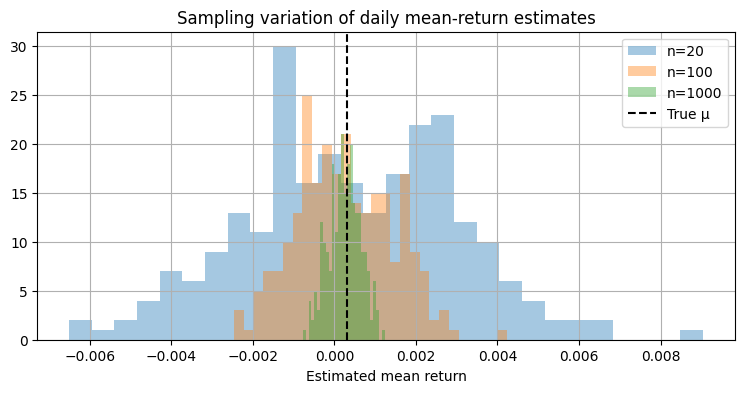

Population mean: 0.00024920483665292624


In [2]:
true_mu = 0.0003
population = rng.normal(true_mu, .012, 100_000)
fig, ax = plt.subplots()
for size in (20, 100, 1000):
    estimates = [rng.choice(population, size=size).mean() for _ in range(250)]
    ax.hist(estimates, bins=28, alpha=.4, label=f'n={size}')
ax.axvline(true_mu, color='black', linestyle='--', label='True μ')
ax.set(title='Sampling variation of daily mean-return estimates', xlabel='Estimated mean return')
ax.legend(); plt.show()
print('Population mean:', population.mean())

## 2. Simple returns, log returns and compounding

**Why this matters in finance / ML.** Most statistical work on prices should operate on returns or price changes, not nonstationary price levels.

**Concept and assumptions.** Simple return R=Pₜ/Pₜ₋₁−1; log return r=ln(Pₜ/Pₜ₋₁). Log returns aggregate by addition across time, simple returns compound by multiplication. The log approximation deteriorates for large moves.

**How to explain the result.** Choose based on question: P&L / portfolio arithmetic favors simple returns; additive time-series modelling often favors log returns.

**Interview questions.** Why not regress two asset price series directly? When are log returns misleading?

### Beginners' view: simple returns and log returns are just two ways to measure change

Simple returns are the easiest to understand. If your portfolio rises from 100 to 110, that is a 10% simple return. If it then falls to 99, the second move is a -9% change from the new level, not a simple subtraction of 10% and 9%.

Log returns are useful because they make time-series math easier. They are close to adding up neatly over many days, which is convenient for statistical models. But for everyday discussion of money made or lost, simple returns are usually more intuitive.

A good beginner rule is:
- Use simple returns when talking about actual portfolio value or P&L.
- Use log returns when you are building mathematical models that treat time in a cleaner way.

This is why the same question may be answered with different return types depending on whether you are explaining performance to an investor or building a model for forecasting.


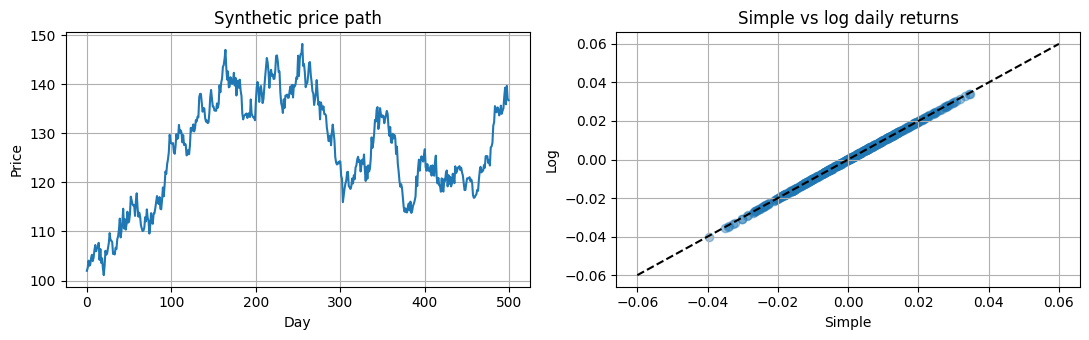

Total simple: 0.3405411802273959 summed log: 0.29307339827230283 conversion: 0.34054118022739627


In [3]:
r = rng.normal(.00025, .015, 500)
prices = 100*np.cumprod(1+r)
simple = pd.Series(prices).pct_change().dropna()
logr = np.log(pd.Series(prices)).diff().dropna()
fig, axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(prices);axes[0].set(title='Synthetic price path',xlabel='Day',ylabel='Price')
axes[1].scatter(simple,logr,alpha=.4);axes[1].plot([-.06,.06],[-.06,.06],'k--');axes[1].set(title='Simple vs log daily returns',xlabel='Simple',ylabel='Log')
plt.tight_layout();plt.show()
print('Total simple:', prices[-1]/prices[0]-1, 'summed log:', logr.sum(), 'conversion:', np.expm1(logr.sum()))

## 3. Mean, median, variance, standard deviation and robust spread

**Why this matters in finance / ML.** Volatility measures risk; the mean can be dominated by a few extreme trades; median/MAD are more resistant.

**Concept and assumptions.** Sample variance uses n−1 (Bessel correction). Std dev is in the same unit as returns. Median absolute deviation (MAD) and IQR are robust alternatives.

**How to explain the result.** A positive average P&L does not imply most days were profitable. Always show scale and tails.

**Interview questions.** Why n−1? Explain standard deviation versus variance.

mean                   70.4289
median                121.3392
sample variance   366,235.0003
sample std            605.1735
IQR                   519.8769
MAD                   265.2464
dtype: float64


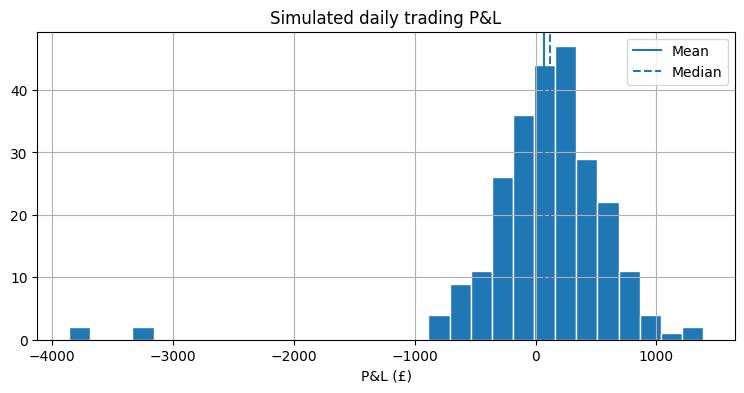

In [4]:
pnl = rng.normal(100,400,250)
pnl[rng.choice(len(pnl),4,replace=False)] -= 3500
s=pd.Series(pnl)
print(pd.Series({'mean':s.mean(),'median':s.median(),'sample variance':s.var(ddof=1),'sample std':s.std(ddof=1),'IQR':s.quantile(.75)-s.quantile(.25),'MAD':stats.median_abs_deviation(s)}))
fig,ax=plt.subplots();ax.hist(pnl,bins=30,edgecolor='white');ax.axvline(s.mean(),label='Mean');ax.axvline(s.median(),ls='--',label='Median');ax.set(title='Simulated daily trading P&L',xlabel='P&L (£)');ax.legend();plt.show()

## 4. Distributions, histograms, ECDFs and density

**Why this matters in finance / ML.** A distribution describes the frequency and magnitude of outcomes, not just their average. Useful for model residuals, VaR, returns, slippage, spreads and anomalous market data.

**Concept and assumptions.** A histogram depends on bin choice. An empirical CDF (ECDF) shows the share of observations at or below x. A kernel density estimate smooths but can hide discrete spikes or tails.

**How to explain the result.** Present distribution shape, central tendency, spread, asymmetry, tails and benchmarks. Compare groups using common bins/axes; plot time evolution separately.

**Interview questions.** How would you communicate return distribution to a portfolio manager? Why plot ECDF?

### Beginners' view: the average is not the whole story

Averages hide important information. A portfolio could have a positive average daily return and still be dangerous if it occasionally has huge losses. That is why we need to look at the whole distribution, not only the center.

Imagine a trading desk with two strategies:
- Strategy A earns 0.05% almost every day.
- Strategy B earns 0.20% on most days but loses 8% on a few rare days.

Both might have similar averages, but they feel very different in real life. A risk manager cares about the tails, not just the center.

This is why histograms, density plots, and percentiles are helpful. They show whether outcomes are usually small, whether outliers are common, and whether losses cluster in the tail.

For beginners, remember: the question is not only "what is the average?" but also "how often do bad outcomes happen?"


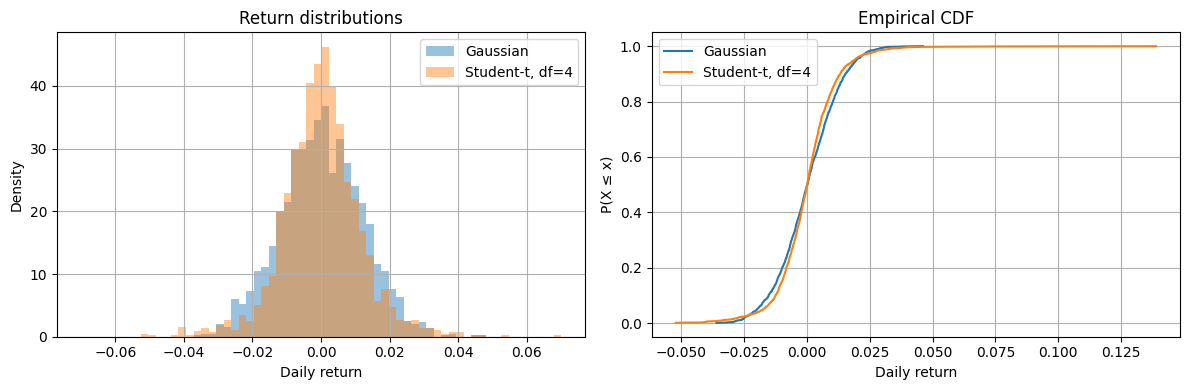

In [5]:
normal = rng.normal(0,.012,2000)
fat = stats.t.rvs(df=4,size=2000,random_state=rng)*.012/np.sqrt(2)
fig,ax=plt.subplots(1,2,figsize=(12,4))
for a,label in [(normal,'Gaussian'),(fat,'Student-t, df=4')]:
    ax[0].hist(a,bins=np.linspace(-.07,.07,65),density=True,alpha=.45,label=label)
    sorted_a=np.sort(a);ax[1].plot(sorted_a,np.arange(1,len(a)+1)/len(a),label=label)
ax[0].set(title='Return distributions',xlabel='Daily return',ylabel='Density');ax[1].set(title='Empirical CDF',xlabel='Daily return',ylabel='P(X ≤ x)')
for a in ax:a.legend()
plt.tight_layout();plt.show()

## 5. Quantiles, percentiles, boxplots and tail behavior

**Why this matters in finance / ML.** Percentiles locate an observation against peers; tail quantiles underpin downside-risk controls.

**Concept and assumptions.** q-th quantile is a threshold below which approximately q of outcomes fall. The 5th percentile of returns is a loss-side tail threshold. Quartiles: 25%, 50%, 75%. Boxplots use median, IQR and whisker conventions, not necessarily min/max.

**How to explain the result.** A 95th percentile latency means 95% of measured latencies are no larger than this threshold. Financial 95% VaR uses the opposite return tail.

**Interview questions.** What is the difference between percentile rank and a percentile?

            0.0100      0.0500    0.2500   0.5000   0.7500   0.9500     0.9900
Rates    -821.4831   -504.3875 -203.6266   9.5601 204.7736 529.5630   878.4960
Credit -2,109.2268 -1,070.3292 -379.5179 -17.0946 337.9909 982.1438 2,067.5584
FX       -817.4928   -536.2378 -249.7877  -1.0640 240.4657 595.2952   842.9048


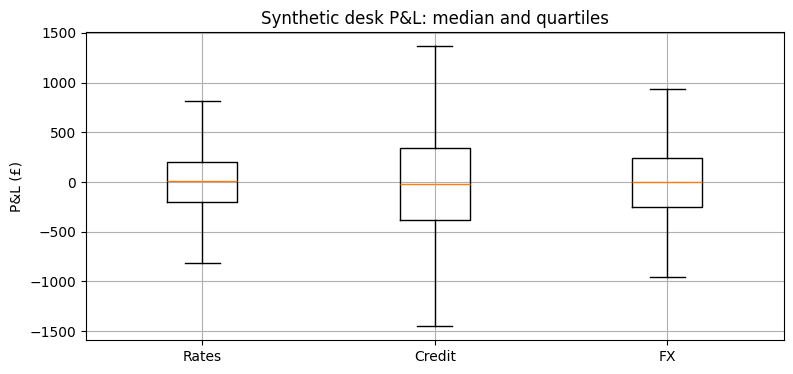

In [6]:
desk = {'Rates': rng.standard_t(6,1000)*280,'Credit':rng.standard_t(3,1000)*450,'FX':rng.normal(0,350,1000)}
frame=pd.DataFrame(desk)
print(frame.quantile([.01,.05,.25,.5,.75,.95,.99]).T)
fig,ax=plt.subplots();ax.boxplot([frame[k] for k in frame],tick_labels=list(frame),showfliers=False);ax.set(title='Synthetic desk P&L: median and quartiles',ylabel='P&L (£)');plt.show()

## 6. Skewness, kurtosis and normality diagnostics

**Why this matters in finance / ML.** Normal risk assumptions often understate financial crashes; skew and heavy tails expose asymmetry and extremes.

**Concept and assumptions.** Skewness quantifies asymmetry. Excess kurtosis is 0 for a normal distribution; positive values often indicate heavy tails. QQ plots compare observed quantiles with a reference distribution. Formal normality tests can reject tiny deviations when n is large.

**How to explain the result.** Show skew/kurtosis with a histogram and QQ plot, not as isolated numbers.

**Interview questions.** Is a large kurtosis always proof of a specific tail distribution?

Skew: -0.04556895237267244 Excess kurtosis: 6.055215662090269
Jarque-Bera: SignificanceResult(statistic=np.float64(3820.202378344237), pvalue=np.float64(0.0))


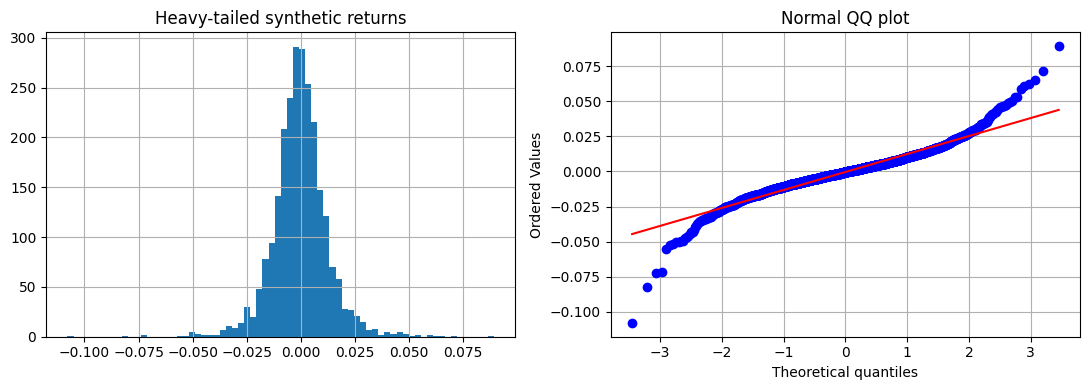

In [7]:
returns = .009*rng.standard_t(4,2500) - .00015
print('Skew:',stats.skew(returns),'Excess kurtosis:',stats.kurtosis(returns))
print('Jarque-Bera:',stats.jarque_bera(returns))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(returns,bins=70);ax[0].set(title='Heavy-tailed synthetic returns')
stats.probplot(returns,dist='norm',plot=ax[1]);ax[1].set_title('Normal QQ plot')
plt.tight_layout();plt.show()

## 7. Common probability distributions and when to use each

**Why this matters in finance / ML.** Select a distribution that matches the nature of the financial variable: continuous returns, event arrivals, default events, counts or waiting times.

**Concept and assumptions.** Normal: measurement noise / rough returns baseline; Student-t: heavy-tailed returns; Bernoulli: one default event; Binomial: defaults across n independent names (unrealistic if correlated); Poisson: counts of rare independent arrivals; Exponential: waiting times under constant hazard; Lognormal: positive multiplicative values.

**How to explain the result.** Never choose a family purely because the histogram looks similar. Check constraints and dependence.

**Interview questions.** What distribution could model defaults? Why does common credit-factor exposure break Binomial assumptions?

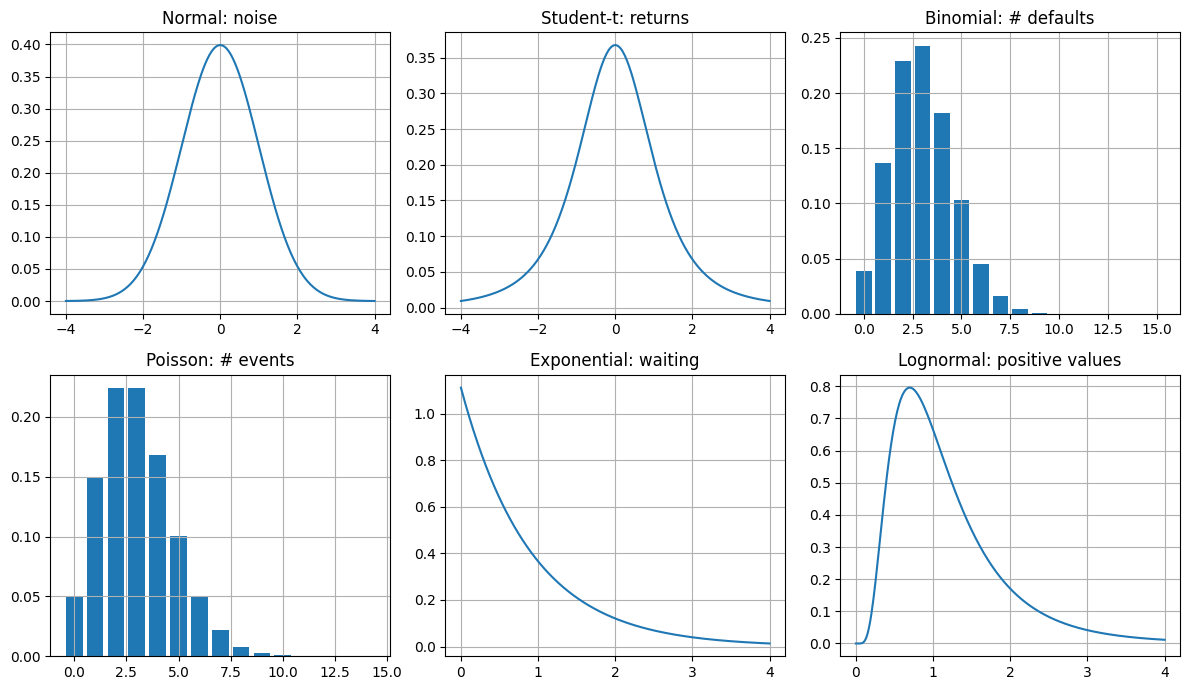

In [8]:
fig,ax=plt.subplots(2,3,figsize=(12,7))
x=np.linspace(-4,4,300);ax[0,0].plot(x,stats.norm.pdf(x));ax[0,0].set_title('Normal: noise')
ax[0,1].plot(x,stats.t.pdf(x,df=3));ax[0,1].set_title('Student-t: returns')
k=np.arange(0,16);ax[0,2].bar(k,stats.binom.pmf(k,20,.15));ax[0,2].set_title('Binomial: # defaults')
k=np.arange(0,15);ax[1,0].bar(k,stats.poisson.pmf(k,3));ax[1,0].set_title('Poisson: # events')
x=np.linspace(0,4,300);ax[1,1].plot(x,stats.expon.pdf(x,scale=.9));ax[1,1].set_title('Exponential: waiting')
ax[1,2].plot(x,stats.lognorm.pdf(x,s=.6));ax[1,2].set_title('Lognormal: positive values')
plt.tight_layout();plt.show()

## 8. Joint, conditional probability and Bayes theorem

**Why this matters in finance / ML.** Default detection and fraud alerts are often rare-event problems. Even a seemingly accurate alert can have low positive predictive value.

**Concept and assumptions.** P(A|B)=P(A∩B)/P(B). Bayes: P(default|flag)=P(flag|default)P(default)/P(flag). Base rates matter. Confusing P(flag|default) with P(default|flag) is a major interview trap.

**How to explain the result.** Discuss base rate, sensitivity, false positive rate and posterior probability.

**Interview questions.** If your model flags a trade, what is the probability it is truly suspicious?

Base default rate: 1.0%; P(default|flag): 14.7%


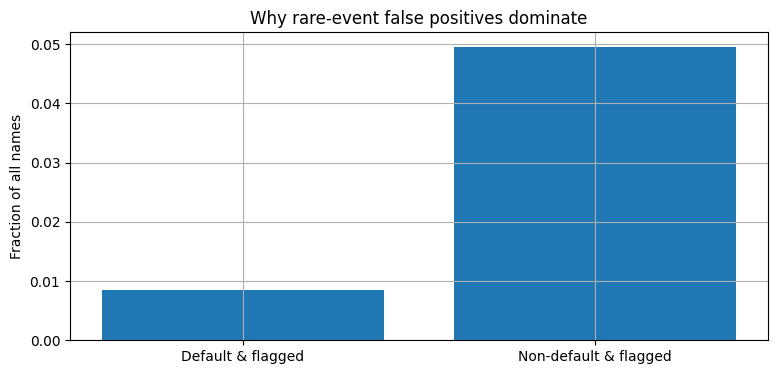

In [9]:
p_default=.01;sensitivity=.85;false_positive=.05
p_flag=sensitivity*p_default+false_positive*(1-p_default)
posterior=sensitivity*p_default/p_flag
print(f'Base default rate: {p_default:.1%}; P(default|flag): {posterior:.1%}')
fig,ax=plt.subplots();ax.bar(['Default & flagged','Non-default & flagged'],[sensitivity*p_default,false_positive*(1-p_default)]);ax.set(title='Why rare-event false positives dominate',ylabel='Fraction of all names');plt.show()

## 9. Covariance, Pearson/Spearman correlations and diversification

**Why this matters in finance / ML.** Covariance drives portfolio variance and risk decomposition. Rank correlations can capture monotonic relationships and be more robust to outliers.

**Concept and assumptions.** Cov(X,Y)=E[(X−μx)(Y−μy)]; corr normalizes covariance to [−1,1]. Pearson measures linear association; Spearman correlates ranks. Correlation ≠ causation; dependence changes under stress.

**How to explain the result.** Explain sign, strength, outlier sensitivity, lag, sample uncertainty and economic mechanism.

**Interview questions.** Can two assets be dependent with zero Pearson correlation?

### Beginners' view: correlation tells us how things move together

Two assets can be related even when they are not identical. If one tends to rise when the other rises, they are positively correlated. If one usually falls while the other rises, they are negatively correlated.

This matters because diversification is about combining assets that do not move in lockstep. If everything moves together during a crisis, diversification can fail at the exact moment you need it most.

For a beginner, a simple rule is: correlation is a description of movement, not a cause. It does not mean one asset caused the other to move. They may both respond to the same larger event, such as inflation news or central bank policy.

Practical example: an investor may hold equities and bonds to reduce risk, but if both assets fall together under stress, the protection is weaker than expected.


In [ ]:
factor = rng.normal(0, 0.012, 1200)
asset_a = 0.0004 + 0.7 * factor + rng.normal(0, 0.008, 1200)
asset_b = 0.0002 - 0.2 * factor + rng.normal(0, 0.01, 1200)
portfolio = 0.5 * asset_a + 0.5 * asset_b
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(asset_a, asset_b, s=8, alpha=0.4)
ax[0].set_title('Two assets with a shared factor')
ax[0].set_xlabel('Asset A return')
ax[0].set_ylabel('Asset B return')
ax[1].plot(np.arange(len(portfolio)), portfolio, alpha=0.8)
ax[1].axhline(0, color='black', linewidth=1)
ax[1].set_title('Portfolio path under stress-like co-movement')
ax[1].set_xlabel('Period')
ax[1].set_ylabel('Portfolio return')
plt.tight_layout(); plt.show()
print('Pairwise correlation:', np.corrcoef(asset_a, asset_b)[0, 1])
print('Portfolio std:', portfolio.std(ddof=1))


Correlations: 
         Equity  Credit   Hedge
Equity  1.0000  0.6664 -0.3624
Credit  0.6664  1.0000 -0.2893
Hedge  -0.3624 -0.2893  1.0000


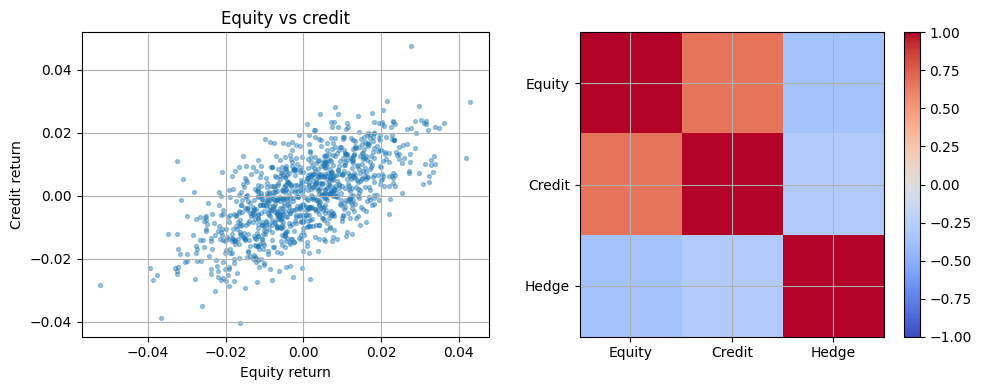

Portfolio volatility: 0.00927547272788163


In [10]:
factor=rng.normal(0,.012,1000)
assets=pd.DataFrame({'Equity':factor+rng.normal(0,.007,1000),'Credit':.7*factor+rng.normal(0,.008,1000),'Hedge':-.3*factor+rng.normal(0,.009,1000)})
print('Correlations: '+chr(10),assets.corr())
fig,ax=plt.subplots(1,2,figsize=(10,4));ax[0].scatter(assets['Equity'],assets['Credit'],s=8,alpha=.4);ax[0].set(title='Equity vs credit',xlabel='Equity return',ylabel='Credit return')
im=ax[1].imshow(assets.corr(),vmin=-1,vmax=1,cmap='coolwarm');ax[1].set_xticks(range(3),assets.columns);ax[1].set_yticks(range(3),assets.columns);plt.colorbar(im,ax=ax[1]);plt.tight_layout();plt.show()
w=np.array([.5,.3,.2]);print('Portfolio volatility:',np.sqrt(w@assets.cov().to_numpy()@w))

# Part II — From samples to decisions: statistical inference

## 10. Sampling distributions, law of large numbers and CLT

**Why this matters in finance / ML.** We infer an unknown expected return from finite samples. The distribution of an estimator governs confidence and tests.

**Concept and assumptions.** Law of large numbers: under suitable assumptions, sample mean converges to expectation. CLT: suitably standardized mean can approach normality as n grows when regularity conditions hold. In finance autocorrelation and infinite/unstable moments can invalidate simple rules.

**How to explain the result.** CLT is about the distribution of sample averages, not a guarantee that daily returns themselves are normal.

**Interview questions.** Does n=30 always make a sample normal?

In [ ]:
x=stats.t.rvs(df=5,size=(3000,100),random_state=rng)
fig,ax=plt.subplots(1,2,figsize=(10,3.5));ax[0].hist(x[:,0],bins=50,density=True);ax[0].set_title('Individual heavy-tailed observations')
ax[1].hist(x.mean(axis=1),bins=50,density=True);ax[1].set_title('Means of n=100 observations');plt.tight_layout();plt.show()

## 11. Standard error vs standard deviation

**Why this matters in finance / ML.** The standard deviation describes dispersion of daily returns; the standard error describes uncertainty about an estimated mean.

**Concept and assumptions.** Under IID and finite variance: SE(mean)=s/√n. With serial correlation, this is typically wrong; heteroskedasticity/autocorrelation-consistent (HAC) methods or block bootstrap can help.

**How to explain the result.** Report mean ± uncertainty, not only daily volatility.

**Interview questions.** Why does adding correlated observations not provide √n improvement?

In [ ]:
values=rng.normal(.0003,.012,252)
print(f'Daily sd={values.std(ddof=1):.4%}; SE(mean)={stats.sem(values):.4%}; mean={values.mean():.4%}')
ns=np.arange(10,501);fig,ax=plt.subplots();ax.plot(ns,.012/np.sqrt(ns));ax.set(title='IID standard error falls as 1/sqrt(n)',xlabel='Sample size',ylabel='SE of daily mean');plt.show()

## 12. Confidence intervals — parametric and bootstrap

**Why this matters in finance / ML.** A point estimate hides estimation uncertainty. We can give a plausible range for mean spread change or expected return.

**Concept and assumptions.** A frequentist 95% CI procedure covers the fixed true parameter in 95% of hypothetical repeated samples (under assumptions). It does not mean 95% probability the realized interval contains a random parameter. t CI uses mean ± t critical × s/√n. Percentile bootstrap resamples observations; use blocks for dependent data.

**How to explain the result.** State interval, estimand, method and assumptions. Also examine whether an effect is economically important.

**Interview questions.** Explain the interpretation of 95% CI and bootstrap limitations.

In [ ]:
spread_savings=rng.normal(.18,.9,140)
nobs=len(spread_savings);mean=spread_savings.mean();se=stats.sem(spread_savings)
ci_t=stats.t.interval(.95,df=nobs-1,loc=mean,scale=se)
boots=np.mean(rng.choice(spread_savings,(4000,nobs),replace=True),axis=1)
ci_b=np.quantile(boots,[.025,.975])
print('Estimated basis-point savings:',round(mean,3),'t CI:',ci_t,'bootstrap CI:',ci_b)
fig,ax=plt.subplots();ax.hist(boots,bins=50);ax.axvline(ci_b[0],ls='--');ax.axvline(ci_b[1],ls='--');ax.set(title='Bootstrap distribution of estimated mean savings',xlabel='bps');plt.show()

## 13. Hypotheses, test statistics and p-values

**Why this matters in finance / ML.** Determine whether an observed improvement can reasonably be explained by chance under an explicit null model.

**Concept and assumptions.** Null H₀ usually sets difference = 0; alternative H₁ != 0 (two-sided), >0 or <0 (predeclared directional). A p-value is P(test statistic at least as extreme as observed | H₀ and model assumptions). Not P(H₀ true | data); not an effect size.

**How to explain the result.** First report effect size, CI, p-value, assumptions and business materiality.

**Interview questions.** What does p=.03 mean? What does it NOT mean?

### Beginners' view: a p-value is not the same as "the result is important"

A p-value is a probability under a specific assumption called the null hypothesis. It tells us how surprising the data would be if there were really no effect. A small p-value means the result seems unlikely under that no-effect assumption.

But it does not automatically mean the result is important in business terms. A very small effect can be statistically significant if the sample is large, yet still be too small to matter after costs and risk are considered.

A beginner-friendly way to think about it:
- p-value answers: "Is this result unusual if there is no real effect?"
- business impact answers: "Is this effect large enough to act on?"

That is why finance teams usually look at both the statistical result and the economic significance before making a decision.


In [ ]:
daily_diff=rng.normal(.00025,.0018,150)
res=stats.ttest_1samp(daily_diff,0)
print('H0: mean improvement=0, H1: !=0')
print('Observed mean:',daily_diff.mean(),'t:',res.statistic,'p:',res.pvalue)
null_t=stats.t.rvs(df=149,size=15000,random_state=rng)
fig,ax=plt.subplots();ax.hist(null_t,bins=70,density=True);ax.axvline(res.statistic,color='red',label='Observed t');ax.axvline(-abs(res.statistic),ls='--',color='red');ax.set(title='Null distribution and observed test statistic');ax.legend();plt.show()

## 14. Significance level, type I/II errors and economic significance

**Why this matters in finance / ML.** Choosing α is a trade-off between false discoveries and missed opportunities. A statistically detectable saving may be economically irrelevant.

**Concept and assumptions.** Type I error: reject true H₀ (false positive), controlled at α for a valid fixed test. Type II: fail to reject false H₀; power=1−β. Statistical significance is not effect size and depends on n.

**How to explain the result.** Distinguish statistical significance from trading costs, capacity and implementation risk.

**Interview questions.** Can an effect be significant but too small to trade?

In [ ]:
effect=.00004
for size in [100,1000,10000,100000]:
    obs=rng.normal(effect,.001,size)
    p=stats.ttest_1samp(obs,0).pvalue
    print(f'n={size:6d} mean={obs.mean():.6f} p={p:.3g}')
print('Daily gain 0.4bps may be below transaction costs even if p<0.05.')

## 15. z-test, one-sample t-test and two-sample Welch t-test

**Why this matters in finance / ML.** Measure whether a strategy return or desk execution cost differs from a benchmark and whether group means differ.

**Concept and assumptions.** z tests require known population variance (rare) or suitable large-sample approximation. One-sample t uses estimated variance; Welch two-sample t allows unequal group variances; pooled Student t assumes equal variances. Independence matters.

**How to explain the result.** Prefer Welch for independent groups with uncertain equal-variance assumption.

**Interview questions.** When should you choose Welch over the classical Student two-sample t-test?

In [ ]:
before=rng.normal(5.0,2.0,130);after=rng.normal(4.5,3.1,110)
r=stats.ttest_ind(before,after,equal_var=False)
print('Spread cost bps: old=',before.mean(),'new=',after.mean(),'Welch t=',r.statistic,'p=',r.pvalue)
fig,ax=plt.subplots();ax.hist(before,alpha=.5,bins=25,label='Old algo');ax.hist(after,alpha=.5,bins=25,label='New algo');ax.set(title='Independent execution cohorts',xlabel='Transaction cost (bps)');ax.legend();plt.show()

## 16. Paired t-test: control matched market conditions

**Why this matters in finance / ML.** Comparing two execution algorithms on the same days/pairs or model errors on the same observation removes common environmental noise.

**Concept and assumptions.** Paired t tests H₀:E[Xᵢ−Yᵢ]=0. The units are matched pairs; their differences should be roughly independent for classical inference. If paired daily differences are autocorrelated, use robust time-series inference.

**How to explain the result.** Pairing often improves precision, but does not fix selection bias or drift.

**Interview questions.** Why are paired comparisons usually better for backtest A/B comparisons?

In [ ]:
market=rng.normal(0,2,130)
a=5+market+rng.normal(0,.7,130)
b=4.8+market+rng.normal(0,.7,130)
print('Paired p:',stats.ttest_rel(a,b).pvalue,'Unpaired Welch p:',stats.ttest_ind(a,b,equal_var=False).pvalue)
fig,ax=plt.subplots();ax.hist(a-b,bins=30);ax.axvline(0,color='k');ax.set(title='Matched daily cost differences: A - B',xlabel='bps');plt.show()

## 17. Tests for proportions, contingency tables and independence

**Why this matters in finance / ML.** Finance uses discrete outcomes: delinquency/no delinquency, successful/failed trade execution, anomaly flagged/not flagged.

**Concept and assumptions.** A binomial test addresses one proportion under independent Bernoulli trials. Chi-square contingency tests explore association in categories; expected-count conditions matter. Fisher exact can help with small 2×2 tables. Correlated obligors violate naive independence.

**How to explain the result.** Give effect as percentages, odds/risk ratios or rate differences alongside p-values.

**Interview questions.** Does a significant chi-square result establish causation?

In [ ]:
defaults=np.array([[14,186],[27,173]]) # rows: segment; columns: default, no default
chi2,p,dof,expected=stats.chi2_contingency(defaults)
print('Table rows segments, columns default/non-default: '+chr(10),defaults)
print('Chi-square p:',p,'expected counts: '+chr(10),expected)
print('Fisher exact p:',stats.fisher_exact(defaults).pvalue)
print('Binomial check 14 defaults in 200 vs hypothesized 10%:',stats.binomtest(14,200,.10).pvalue)

## 18. Nonparametric comparisons and permutation tests

**Why this matters in finance / ML.** Cost savings and residuals can be skewed, with outliers or uncertain parametric assumptions.

**Concept and assumptions.** Mann–Whitney U tests distributional rank differences (not universally a test of medians). Wilcoxon signed-rank is for paired data with suitable symmetry. Permutation tests are exact under exchangeability; naive shuffling is invalid for dependent time series.

**How to explain the result.** Nonparametric does not mean assumption-free. Explain why observations could or could not be permuted.

**Interview questions.** What is exchangeability? When is Mann–Whitney not a pure median test?

In [ ]:
x=rng.lognormal(1,.6,100);y=rng.lognormal(.9,.7,110)
print('Mann-Whitney:',stats.mannwhitneyu(x,y,alternative='two-sided'))
observed=x.mean()-y.mean();pooled=np.r_[x,y];perms=[]
for _ in range(1500):
    z=rng.permutation(pooled);perms.append(z[:len(x)].mean()-z[len(x):].mean())
p_perm=(1+np.sum(np.abs(perms)>=abs(observed)))/(len(perms)+1)
print('Observed mean diff:',observed,'permutation p:',p_perm)
fig,ax=plt.subplots();ax.hist(perms,bins=45);ax.axvline(observed,color='r');ax.set_title('Permutation distribution under exchangeability');plt.show()

## 19. Multiple comparisons, data snooping and false discoveries

**Why this matters in finance / ML.** Scanning hundreds of trading factors or hyperparameters guarantees apparently good findings by chance, even without signal.

**Concept and assumptions.** If m independent true nulls are tested at α=.05, expected false rejections are 0.05m. Bonferroni controls family-wise error by α/m. Benjamini–Hochberg (BH) controls expected false discovery proportion under appropriate dependence assumptions. Final holdout remains necessary.

**How to explain the result.** Disclose total number of attempted signals, not just the winner.

**Interview questions.** Why do factor discovery and repeated backtesting demand multiple-testing control?

In [ ]:
m=200
pvals=rng.uniform(size=m) # all nulls
alpha=.05
order=np.argsort(pvals); ranked=pvals[order]
bh_candidates=np.where(ranked <= alpha*np.arange(1,m+1)/m)[0]
bh_cut=ranked[bh_candidates[-1]] if len(bh_candidates) else 0
print('Unadjusted false positives:',int(np.sum(pvals<alpha)))
print('Bonferroni:',int(np.sum(pvals<alpha/m)),'BH discoveries:',int(np.sum(pvals<=bh_cut)))
fig,ax=plt.subplots();ax.scatter(np.arange(1,m+1),ranked,s=10,label='Sorted p');ax.plot(np.arange(1,m+1),alpha*np.arange(1,m+1)/m,label='BH threshold');ax.set(xlabel='Rank',ylabel='p-value',title='Multiple hypothesis testing');ax.legend();plt.show()

## 20. Power, detectable effect size and sample-size planning

**Why this matters in finance / ML.** A backtest or A/B test may lack the sensitivity to detect a plausible trading cost reduction. Plan before running experiments.

**Concept and assumptions.** Approximate two-sided mean test sample size n ≈ ((z₁₋α/₂+z₁₋β)σ/δ)² for IID observations and known-effect approximation. Effect δ, noise σ, power 1−β determine n. Autocorrelation increases effective sample needs.

**How to explain the result.** Report the smallest economically interesting effect and the power to detect it.

**Interview questions.** What happens to required sample size when you halve the desired detectable effect?

In [ ]:
alpha=.05;power=.80;sigma=2.0 # cost bps
zsum=stats.norm.ppf(1-alpha/2)+stats.norm.ppf(power)
for delta in [.2,.4,.8]:
    print(f'Detect {delta:.1f}bps effect: ~{np.ceil((zsum*sigma/delta)**2):.0f} IID paired observations')
fig,ax=plt.subplots();delta=np.linspace(.15,1.0,100);ax.plot(delta,(zsum*sigma/delta)**2);ax.set(xlabel='Effect to detect (bps)',ylabel='Approximate sample size',title='Power / effect size trade-off');plt.show()

# Part III — Statistical models supporting ML

## 21. Likelihood, log-likelihood and maximum likelihood estimation

**Why this matters in finance / ML.** Many ML estimators, from Gaussian risk models to logistic regression, are fit by maximizing likelihood (or minimizing negative log-likelihood).

**Concept and assumptions.** Likelihood treats observed data as fixed and model parameters as varying. Independent Gaussian observations imply a log-likelihood combining squared deviations and variance. MLE differs from Bayesian posterior estimation.

**How to explain the result.** Tell the interviewer: maximizing normal likelihood in the mean is equivalent to minimizing squared error for fixed variance.

**Interview questions.** What is log-likelihood? Why take logs of products of probabilities?

In [ ]:
x=rng.normal(.002,.015,300)
mu_grid=np.linspace(-.004,.008,150);sigma=.015
ll=np.array([stats.norm.logpdf(x,loc=mu,scale=sigma).sum() for mu in mu_grid])
fig,ax=plt.subplots();ax.plot(mu_grid,ll);ax.axvline(x.mean(),ls='--',color='black',label='Sample mean / MLE');ax.set(title='Gaussian log-likelihood vs assumed mean',xlabel='μ',ylabel='Log-likelihood');ax.legend();plt.show()
print('MLE mean:',x.mean(),'MLE sigma:',np.std(x,ddof=0))

## 22. Linear regression, coefficients, residuals and R²

**Why this matters in finance / ML.** Risk-factor exposures, sensitivity modelling and forecasting often begin with linear regression as an interpretable benchmark.

**Concept and assumptions.** OLS minimizes sum of squared residuals. β estimates linear conditional association, not necessarily causality. R² measures variance accounted for relative to constant baseline in sample; can be negative out of sample. Assumptions for coefficient inference differ from those for predictive utility.

**How to explain the result.** Report beta, intercept, residual behavior, test performance and plausible driver relationships.

**Interview questions.** What does beta mean in a factor model? Can test R² be negative?

### Beginners' view: regression is a simple way to describe a trend

Regression is a way to ask: "If one variable changes, how does another variable tend to change alongside it?" In finance, this often means asking whether a factor such as market return or liquidity explains part of an asset's return.

The slope tells us the direction and size of the relationship. If the slope is positive, higher values of the factor are associated with higher outcomes. If it is negative, the relationship goes the other way.

But regression is not magic. It is only a model. It can be useful, but it can also be wrong if the relationship is unstable, if the data are noisy, or if a hidden factor is actually driving both variables.

A beginner-friendly way to use it: start with a clear graph, look at the pattern, check whether the residuals still look random, and then decide whether the relationship is stable enough to use in decision-making.


In [ ]:
x = rng.normal(0, 1, 500)
y = 0.8 * x + rng.normal(0, 1.6, 500)
model = LinearRegression().fit(x.reshape(-1, 1), y)
fit = model.predict(x.reshape(-1, 1))
resid = y - fit
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, s=12, alpha=0.5)
ax[0].plot(np.sort(x), model.predict(np.sort(x).reshape(-1, 1)), color='black')
ax[0].set_title('Linear relationship with noise')
ax[0].set_xlabel('Signal x')
ax[0].set_ylabel('Target y')
ax[1].scatter(fit, resid, s=8, alpha=0.5)
ax[1].axhline(0, color='black', linestyle='--')
ax[1].set_title('Residuals against fitted values')
ax[1].set_xlabel('Fitted value')
ax[1].set_ylabel('Residual')
plt.tight_layout(); plt.show()
print('Slope:', model.coef_[0], 'R²:', r2_score(y, fit))


In [ ]:
market=rng.normal(.0002,.012,400)
asset=.0001+1.25*market+rng.normal(0,.008,400)
model=LinearRegression().fit(market.reshape(-1,1),asset)
pred=model.predict(market.reshape(-1,1));resid=asset-pred
print('Alpha:',model.intercept_,'Beta:',model.coef_[0],'Train R2:',r2_score(asset,pred))
fig,ax=plt.subplots(1,2,figsize=(11,4));ax[0].scatter(market,asset,s=8,alpha=.45);ax[0].plot(np.sort(market),model.predict(np.sort(market).reshape(-1,1)),color='black');ax[0].set(title='Factor regression',xlabel='Market',ylabel='Asset')
ax[1].scatter(pred,resid,s=8);ax[1].axhline(0,color='k');ax[1].set(title='Residual diagnostic',xlabel='Fitted',ylabel='Residual');plt.tight_layout();plt.show()

## 23. Multicollinearity, conditioning and ridge regression

**Why this matters in finance / ML.** Highly correlated risk factors can make factor loadings unstable even if portfolio prediction remains reasonable.

**Concept and assumptions.** When X columns are close to linearly dependent, coefficient variance explodes; ridge penalizes squared coefficients and stabilizes them. Standardize features before regularizing. VIF identifies collinearity, but does not itself prove poor predictive performance.

**How to explain the result.** Separate stability of explanation from accuracy of predictions.

**Interview questions.** Why can two coefficients flip signs after minor data changes?

In [ ]:
nobs=150;x1=rng.normal(size=nobs);x2=x1+.03*rng.normal(size=nobs)
X=np.c_[x1,x2];y=.5*x1+.5*x2+.3*rng.normal(size=nobs)
for alpha in [0,1,20]:
    fit=LinearRegression().fit(X,y) if alpha==0 else make_pipeline(StandardScaler(),Ridge(alpha=alpha)).fit(X,y)
    coef=fit.coef_ if alpha==0 else fit[-1].coef_
    print('alpha=',alpha,'coefficients=',np.round(coef,3))
print('Correlation among predictors:',np.corrcoef(x1,x2)[0,1])

## 24. Heteroskedasticity and uncertainty

**Why this matters in finance / ML.** Errors in financial returns often have time-varying variance, so conventional OLS coefficient standard errors can be misleading.

**Concept and assumptions.** Homoskedastic means constant conditional residual variance; heteroskedastic means it varies with predictors/time. Robust (HC) standard errors help for independent observations; HAC helps with both serial dependence and heteroskedasticity. Neither repairs misspecification nor leakage.

**How to explain the result.** Plot residuals versus fitted values; choose robust uncertainty model based on dependence structure.

**Interview questions.** Does heteroskedasticity bias OLS coefficients by itself?

In [ ]:
x=rng.uniform(0,4,500);err=rng.normal(size=500)*(.25+.5*x);y=1+.7*x+err
fit=LinearRegression().fit(x.reshape(-1,1),y);resid=y-fit.predict(x.reshape(-1,1))
fig,ax=plt.subplots();ax.scatter(x,resid,s=10,alpha=.4);ax.axhline(0,color='black');ax.set(title='Funnel-shaped residual variance',xlabel='Financial exposure proxy',ylabel='Residual');plt.show()
try:
 import statsmodels.api as sm
 ols=sm.OLS(y,sm.add_constant(x)).fit()
 print('Slope SE classical:',ols.bse[1],'HC3:',ols.get_robustcov_results(cov_type='HC3').bse[1])
except ImportError:
 print('Optional: pip install statsmodels for robust SE comparison')

## 25. Autocorrelation, effective sample size and HAC standard errors

**Why this matters in finance / ML.** Daily P&L, volatility, spread and signals exhibit dependence: 252 observations do not necessarily equal 252 independent pieces of information.

**Concept and assumptions.** Lag-k autocorrelation Corr(Xₜ,Xₜ₋ₖ) reveals persistence. For AR(1), an approximate mean effective n is n(1−ρ)/(1+ρ), for positive ρ and under stylized conditions. HAC (Newey–West) adjusts standard errors without assuming IID residuals.

**How to explain the result.** Show ACF and compare naive with adjusted SE; state that effective-n is approximate.

**Interview questions.** Why can naive Sharpe t-statistics overstate confidence?

In [ ]:
rho=.7;eps=rng.normal(0,.01,500);series=np.zeros(500)
for i in range(1,500):series[i]=rho*series[i-1]+eps[i]
acfs=[pd.Series(series).autocorr(lag=k) for k in range(1,21)]
fig,ax=plt.subplots();ax.bar(np.arange(1,21),acfs);ax.set(title='Sample autocorrelation of synthetic AR(1) process',xlabel='Lag',ylabel='Autocorrelation');plt.show()
print('Naive SE:',stats.sem(series),'approx effective n:',len(series)*(1-rho)/(1+rho))
try:
 import statsmodels.api as sm
 m=sm.OLS(series,np.ones((len(series),1))).fit()
 print('Classical SE:',m.bse[0], 'HAC(10) SE:',m.get_robustcov_results(cov_type='HAC',maxlags=10).bse[0])
except ImportError:pass

## 26. Outliers, winsorization, robust estimation and data quality

**Why this matters in finance / ML.** Single market-data errors or genuine shocks can dominate regression and scale estimates. Silently dropping extremes destroys risk information.

**Concept and assumptions.** An outlier can be a data-quality error, rare genuine event or regime shift. Winsorization clips tail values, trimming removes them. Robust regression/median and carefully designed anomaly detection are alternatives. Fit any preprocessing using training data only.

**How to explain the result.** Explain diagnostic evidence before treatment; compare retained-tail and transformed results.

**Interview questions.** When should you not remove a 10-sigma return?

In [ ]:
r=rng.normal(0,.01,800);r[30]=.18;r[400]=-.25
lo,hi=np.quantile(r,[.01,.99]);clipped=np.clip(r,lo,hi)
print('Raw sd:',r.std(ddof=1),'Winsorized sd:',clipped.std(ddof=1))
fig,ax=plt.subplots();ax.plot(r,label='Original',alpha=.55);ax.plot(clipped,label='Winsorized',alpha=.7);ax.set(title='Outlier handling changes measured volatility');ax.legend();plt.show()

## 27. Bias–variance trade-off and overfitting

**Why this matters in finance / ML.** An elaborate financial predictor can fit historical noise and collapse in another market period.

**Concept and assumptions.** Bias captures systematic approximation error; variance captures sensitivity to sample. Training error usually falls as flexibility increases, while test error can turn upward. Regularization, feature control and honest time split help.

**How to explain the result.** Use held-out performance to detect model complexity that does not generalize.

**Interview questions.** Why can a complex model outperform in-sample but underperform out-of-sample?

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline as mkpipe
from sklearn.metrics import mean_squared_error
x=rng.uniform(-2,2,130);y=.8*x-.25*x**2+rng.normal(0,.8,130)
idx=rng.permutation(len(x));tr,te=idx[:75],idx[75:]
for degree in [1,2,5,15]:
 mod=mkpipe(PolynomialFeatures(degree),LinearRegression()).fit(x[tr,None],y[tr])
 print('degree',degree,'train MSE',round(mean_squared_error(y[tr],mod.predict(x[tr,None])),3),'test MSE',round(mean_squared_error(y[te],mod.predict(x[te,None])),3))

# Part IV — ML validation and model-risk statistics

## 28. Random splits, temporal leakage and walk-forward testing

**Why this matters in finance / ML.** Random train/test shuffling usually leaks time information when forecasting financial data.

**Concept and assumptions.** Training must precede testing; transformations, labels and feature construction must respect the as-of date. Rolling/expanding windows mimic deployment. Gap/purge observations if overlapping forward labels cross boundaries.

**How to explain the result.** Demonstrate genuine out-of-sample performance with chronological folds and untouched final holdout.

**Interview questions.** What is look-ahead bias? When do you need purging and an embargo?

### Beginners' view: leakage means using information you should not have had

A model is not useful if it learns from the future. In finance, this is a big problem because we often train models on historical data and then claim they work on new data.

If you accidentally include information that would not have been available at the time you made the prediction, the model may look great during testing but fail badly in real life. This is called data leakage.

A simple example: imagine trying to predict next month's default risk using the default outcome from the same month. That information would not have been known before the decision, so it would make the model unrealistically good.

For beginners, the rule is simple: by the time you predict, your features must come only from information available at that time. This is why time-based validation is so important.


In [ ]:
from sklearn.model_selection import TimeSeriesSplit
nobs=300;dates=pd.bdate_range('2024-01-01',periods=nobs)
cv=TimeSeriesSplit(n_splits=4,gap=5)
fig,ax=plt.subplots(figsize=(10,3))
for i,(train,test) in enumerate(cv.split(dates)):
 ax.scatter(train,np.ones(len(train))*i,marker='|',s=25,label='Train' if i==0 else None)
 ax.scatter(test,np.ones(len(test))*i,marker='|',s=25,label='Test' if i==0 else None)
ax.set(title='TimeSeriesSplit: train before test, with a gap',xlabel='Observation index',ylabel='Fold');ax.legend();plt.show()

## 29. Regression error metrics, baselines and confidence

**Why this matters in finance / ML.** Even a statistically significant predictor might not beat a trivial forecast after costs.

**Concept and assumptions.** MSE penalizes large errors; RMSE has units of target; MAE is less sensitive to outliers. Out-of-sample R² compares against a baseline (be careful which baseline mean is permitted to use). Correlated forecast errors mean standard CI methods can fail.

**How to explain the result.** Compare against historical mean, random walk or simple industry baseline.

**Interview questions.** Why is accuracy not an appropriate metric for continuous returns?

In [ ]:
nobs=800
x=rng.normal(0,.01,nobs)
y=.2*np.r_[0,x[:-1]]+rng.normal(0,.012,nobs)
tr=600;model=LinearRegression().fit(x[:tr,None],y[:tr]);pred=model.predict(x[tr:,None]);base=np.repeat(y[:tr].mean(),len(pred))
for label,p in [('Model',pred),('Train-mean baseline',base)]:
 print(label,'MAE:',mean_absolute_error(y[tr:],p),'RMSE:',np.sqrt(mean_squared_error(y[tr:],p)))
fig,ax=plt.subplots();ax.plot(y[tr:tr+70],label='Actual');ax.plot(pred[:70],label='Predicted');ax.set_title('Forward return predictions (synthetic)');ax.legend();plt.show()

## 30. Confusion matrix, precision, recall, specificity and F1

**Why this matters in finance / ML.** Rare credit defaults, fraud and market-data anomalies make raw accuracy dangerously misleading.

**Concept and assumptions.** TP/FP/TN/FN populate a confusion matrix. Precision=TP/(TP+FP); Recall=TP/(TP+FN); Specificity=TN/(TN+FP). F1 harmonically averages precision and recall. Denominators must be defined and zero-division handled.

**How to explain the result.** Make the cost of false alarms versus missed defaults explicit; compare with always-negative baseline.

**Interview questions.** Why can 99% accuracy be useless for a 1% default problem?

### Beginners' view: accuracy can be misleading when the event is rare

Suppose only 1% of customers default. A model that says "no default" for everyone would be right 99% of the time. That sounds great, but it fails the real goal because it misses all of the default cases.

This is why a single metric like accuracy is often not enough. In finance, rare events matter a lot, so we usually also look at:
- precision: among the people we flagged, how many truly defaulted?
- recall: how many actual defaults did we catch?
- F1: a balance between the two.

A beginner-friendly idea is: if the event is rare, do not celebrate a high accuracy score unless the model is actually finding the risky cases.


In [ ]:
nobs=2500;truth=(rng.random(nobs)<.015).astype(int)
scores=np.where(truth==1,rng.beta(5,3,nobs),rng.beta(2,12,nobs))
pred=(scores>=.4).astype(int)
print('Accuracy:',accuracy_score(truth,pred),'Precision:',precision_score(truth,pred,zero_division=0),'Recall:',recall_score(truth,pred,zero_division=0),'F1:',f1_score(truth,pred,zero_division=0))
cm=confusion_matrix(truth,pred)
fig,ax=plt.subplots();ax.imshow(cm,cmap='Blues');
for (i,j),value in np.ndenumerate(cm):ax.text(j,i,value,ha='center',va='center',color='red')
ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicted',ylabel='Actual',title='Confusion matrix: rare-event detection');plt.show()

## 31. ROC-AUC, precision–recall trade-offs and decision thresholds

**Why this matters in finance / ML.** A credit decision or alert score must be converted to an action while balancing operational costs.

**Concept and assumptions.** ROC-AUC measures pairwise ranking probability; PR curves emphasize positive-class quality when positives are rare. A threshold changes recall and precision, not inherent ranking AUC. ROC-AUC may appear high even with many false alerts.

**How to explain the result.** Select thresholds based on costs, capacity, calibration and policy; do not optimize on the final holdout.

**Interview questions.** Why may PR-AUC be more informative than ROC-AUC for anomaly detection?

In [ ]:
from sklearn.metrics import roc_curve,precision_recall_curve,average_precision_score
fpr,tpr,_=roc_curve(truth,scores);prec,rec,_=precision_recall_curve(truth,scores)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(fpr,tpr);ax[0].plot([0,1],[0,1],'k--');ax[0].set(title=f'ROC AUC={roc_auc_score(truth,scores):.3f}',xlabel='False positive rate',ylabel='True positive rate')
ax[1].plot(rec,prec);ax[1].axhline(truth.mean(),ls='--',color='black',label='Base rate');ax[1].set(title=f'PR AP={average_precision_score(truth,scores):.3f}',xlabel='Recall',ylabel='Precision');ax[1].legend();plt.tight_layout();plt.show()

## 32. Probability calibration, reliability and Brier score

**Why this matters in finance / ML.** Financial decisions use default probabilities and expected losses, not merely ranking scores. A model output of 0.20 should correspond to roughly 20% event frequency in comparable cases.

**Concept and assumptions.** Calibration assesses whether predicted probabilities match observed frequencies. Brier score is mean squared error for binary probability forecasts. Log loss strongly penalizes confident errors. Calibration can drift across regimes.

**How to explain the result.** Separate discrimination (ranking) from calibration (probability reliability).

**Interview questions.** Can a high-AUC model be badly calibrated?

In [ ]:
from sklearn.calibration import calibration_curve
# simulate a probability model with systematic overconfidence
p_true=rng.beta(1.3,9,5000)
y_event=rng.binomial(1,p_true)
p_reported=np.clip(p_true**.65,0,1)
frac,p_bin=calibration_curve(y_event,p_reported,n_bins=10,strategy='quantile')
fig,ax=plt.subplots();ax.plot([0,1],[0,1],'k--',label='Perfect calibration');ax.plot(p_bin,frac,'o-',label='Overconfident model');ax.set(xlabel='Predicted event probability',ylabel='Observed event fraction',title='Credit PD calibration');ax.legend();plt.show()
print('Brier:',brier_score_loss(y_event,p_reported))

## 33. Bootstrapped ML metric uncertainty and dependence

**Why this matters in finance / ML.** Validation numbers like AUC=0.76 need confidence ranges, especially for few defaults.

**Concept and assumptions.** Ordinary paired row bootstrap samples (prediction, label) pairs together and assumes exchangeable test rows. For clustered loans, sample whole borrowers/issuers; for time series, use blocks. Refit models inside bootstrap when measuring total model-building variability.

**How to explain the result.** Report uncertainty and support size, not only a single metric; bootstrap samples without both classes cannot define AUC.

**Interview questions.** Should you bootstrap labels and predictions independently?

In [ ]:
pairs=np.c_[truth,scores];aucs=[]
for _ in range(900):
 sample=pairs[rng.integers(0,len(pairs),len(pairs))]
 if len(np.unique(sample[:,0]))==2:aucs.append(roc_auc_score(sample[:,0],sample[:,1]))
print('Test ROC-AUC:',roc_auc_score(truth,scores),'row-bootstrap 95% CI:',np.quantile(aucs,[.025,.975]))
fig,ax=plt.subplots();ax.hist(aucs,bins=35);ax.set_title('Bootstrap metric uncertainty (IID assumption)');plt.show()

# Part V — Financial time series, portfolio risk and regimes

## 34. Stationarity, rolling statistics and ADF intuition

**Why this matters in finance / ML.** Forecasting models assuming fixed distributions can fail as mean, volatility or correlations change over time.

**Concept and assumptions.** Weak stationarity implies constant mean and variance and autocovariance dependent on lag, under standard definitions. ADF tests unit-root null vs specified stationary alternatives; KPSS has a stationarity null. Both are sensitive to specification, sample and structural breaks.

**How to explain the result.** Visualize rolling mean/volatility before formal testing; distinguish stationarity from absence of autocorrelation.

**Interview questions.** Why might share prices be nonstationary but returns more nearly stationary?

In [ ]:
drift=np.r_[np.repeat(.0002,350),np.repeat(-.0002,350)]
vol=np.r_[np.repeat(.008,350),np.repeat(.022,350)]
ret=drift+rng.normal(size=700)*vol
series=pd.Series(ret)
fig,ax=plt.subplots(2,1,figsize=(10,6),sharex=True);ax[0].plot(series);ax[0].plot(series.rolling(50).mean(),label='Rolling mean');ax[0].legend();ax[0].set_title('Regime-changing daily returns')
ax[1].plot(series.rolling(50).std());ax[1].set(title='50-day rolling volatility',xlabel='Day');plt.tight_layout();plt.show()
try:
 from statsmodels.tsa.stattools import adfuller
 print('ADF p-value:',adfuller(ret,autolag='AIC')[1], '(null = unit root; not a full guarantee of stationarity)')
except ImportError:pass

## 35. Volatility clustering, EWMA and GARCH intuition

**Why this matters in finance / ML.** Risk models must recognize that shocks tend to be followed by periods of elevated volatility.

**Concept and assumptions.** ARCH effects mean conditional variance depends on previous shocks; GARCH adds lagged variance. EWMA variance σ²ₜ=λσ²ₜ₋₁+(1−λ)r²ₜ₋₁. Look at autocorrelation of squared returns, not only raw returns.

**How to explain the result.** Explain why a constant-volatility Gaussian model can miss risk after a shock.

**Interview questions.** Why can return autocorrelation be low while squared-return autocorrelation is high?

### Beginners' view: volatility often comes in bursts

Markets do not always move at a steady pace. Sometimes calm periods last for weeks, and then a sudden shock is followed by more turbulence. This is called volatility clustering.

A simple example: after a major news event, prices may be more erratic for a while. If your model assumes the volatility is always the same, it will underestimate risk during these turbulent periods.

That is why risk teams often use rolling volatility or EWMA-style models: they respond to recent market behavior rather than assuming everything is stable.

For beginners, the key idea is: recent shocks often tell you something about the near-term risk environment.


In [ ]:
rho = 0.75
x = np.zeros(600)
noise = rng.normal(0, 0.012, 600)
for t in range(1, 600):
    x[t] = rho * x[t-1] + noise[t]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x)
ax[0].set_title('Autoregressive series with persistence')
ax[0].set_xlabel('Time')
ax[0].set_ylabel('Value')
ax[1].plot(pd.Series(x).rolling(30).std(), label='30-day rolling vol')
ax[1].set_title('Volatility clustering signal')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('Rolling volatility')
ax[1].legend()
plt.tight_layout(); plt.show()
print('Lag-1 autocorrelation:', pd.Series(x).autocorr(lag=1))
print('Lag-1 squared autocorrelation:', pd.Series(x ** 2).autocorr(lag=1))


In [ ]:
nobs=700;v=np.empty(nobs);eps=np.empty(nobs);v[0]=.0001;eps[0]=rng.normal()*np.sqrt(v[0])
for t in range(1,nobs):
 v[t]=.000004+.10*eps[t-1]**2+.86*v[t-1]
 eps[t]=rng.normal()*np.sqrt(v[t])
ewma=np.empty(nobs);ewma[0]=np.var(eps[:80]);lam=.94
for t in range(1,nobs):ewma[t]=lam*ewma[t-1]+(1-lam)*eps[t-1]**2
fig,ax=plt.subplots();ax.plot(np.sqrt(v),label='True latent sigma');ax.plot(np.sqrt(ewma),label='EWMA forecast sigma',alpha=.85);ax.set(title='Synthetic clustered volatility',xlabel='Day');ax.legend();plt.show()
print('Lag-1 return autocorr:',pd.Series(eps).autocorr(),'lag-1 squared-return autocorr:',pd.Series(eps**2).autocorr())

## 36. Value at Risk and Expected Shortfall

**Why this matters in finance / ML.** Risk management needs tail-loss quantification beyond a single volatility measure.

**Concept and assumptions.** Loss L=−return (for unit notional). VaR at 95% is the 95th percentile of loss; ES at 95% is average loss in the worst 5% (for a continuous distribution). Historical estimates need substantial tail samples and may miss unseen crises.

**How to explain the result.** State horizon, confidence level, loss units, model and historical window.

**Interview questions.** Why does ES reveal tail severity that VaR does not?

In [ ]:
returns=.009*rng.standard_t(4,3000);loss=-returns
var95=np.quantile(loss,.95);es95=loss[loss>=var95].mean()
print(f'One-day historical 95% VaR: {var95:.2%}; ES: {es95:.2%}')
fig,ax=plt.subplots();ax.hist(loss,bins=80);ax.axvline(var95,color='red',label='VaR 95%');ax.axvline(es95,color='black',ls='--',label='ES 95%');ax.set(title='Synthetic loss distribution',xlabel='Loss / notional');ax.legend();plt.show()

## 37. Sharpe ratio, drawdowns and uncertainty of backtests

**Why this matters in finance / ML.** A trading signal needs risk-adjusted evaluation rather than relying on raw average return or classification accuracy.

**Concept and assumptions.** Annualized Sharpe ~ √252 × mean(excess daily return)/daily std under stable IID-like scaling assumptions. Max drawdown measures peak-to-trough cumulative wealth loss. Naive annualization/SE are unreliable with serial correlation, fat tails and changing regimes.

**How to explain the result.** Show net-of-cost returns, Sharpe, drawdown, turnover and uncertainty with realistic market impact.

**Interview questions.** Why is a Sharpe ratio of 2 not automatically statistically convincing?

In [ ]:
daily=rng.normal(.0004,.012,750)
wealth=np.cumprod(1+daily);drawdown=wealth/np.maximum.accumulate(wealth)-1
sharpe=np.sqrt(252)*daily.mean()/daily.std(ddof=1)
print('Illustrative annualized Sharpe:',sharpe,'max drawdown:',drawdown.min())
fig,ax=plt.subplots(2,1,figsize=(10,6),sharex=True);ax[0].plot(wealth);ax[0].set_title('Synthetic strategy wealth');ax[1].fill_between(np.arange(len(drawdown)),drawdown,0);ax[1].set(title='Underwater / drawdown',xlabel='Day');plt.tight_layout();plt.show()

## 38. Structural breaks, concept drift and monitoring

**Why this matters in finance / ML.** Models trained in one market regime can deteriorate when inflation, volatility or trading behavior changes.

**Concept and assumptions.** Covariate drift P(X) changes; concept drift conditional P(Y|X) changes; label/prior shift P(Y) changes. PSI, KS and KS p-values are diagnostics with limitations; prediction performance and calibration should be monitored with time and segments.

**How to explain the result.** Investigate material changes using effect magnitudes and economic context, not only highly sensitive tests.

**Interview questions.** How would you detect that a credit default model is drifting?

In [ ]:
old=rng.normal(0,1,600);new=rng.normal(.55,1.25,600)
print('Two-sample KS:',stats.ks_2samp(old,new))
fig,ax=plt.subplots();ax.hist(old,density=True,bins=30,alpha=.5,label='Training window');ax.hist(new,density=True,bins=30,alpha=.5,label='Later window');ax.set(title='Synthetic feature drift: liquidity metric');ax.legend();plt.show()

## 39. Spurious regression, cointegration and pairs-trading caution

**Why this matters in finance / ML.** Two trending asset prices can have high correlation without a usable economic relationship.

**Concept and assumptions.** Regressing unrelated nonstationary series can generate spurious significance. Cointegration implies a stationary linear combination of individually integrated series under suitable assumptions. Pair selection, structural breaks, trading costs and multiple-testing controls are crucial.

**How to explain the result.** Distinguish correlation of prices from stationarity of a potential spread and economic plausibility.

**Interview questions.** What does cointegration add beyond correlation?

In [ ]:
x=np.cumsum(rng.normal(size=800));y=np.cumsum(rng.normal(size=800))
print('Independent random-walk price correlation (sample):',np.corrcoef(x,y)[0,1])
fig,ax=plt.subplots();ax.plot(x,label='Price index X');ax.plot(y,label='Price index Y');ax.set(title='Two independent synthetic random walks');ax.legend();plt.show()
try:
 from statsmodels.tsa.stattools import coint
 print('Cointegration p-value:',coint(x,y)[1], '(single simulation; no guarantee)')
except ImportError:pass

# Part VI — Interview synthesis, exercises, model answers

## 40. The interview explanation framework

For *any* statistical question, structure your answer:

1. **Business question**: What finance decision are we supporting? (risk capital, alpha, expected loss, anomaly alert).
2. **Quantity/estimand**: What exactly are we estimating or testing? (mean difference, tail quantile, calibrated PD).
3. **Method**: Why this statistic/model? What alternatives?
4. **Assumptions**: Independence, time stability, sampling and distribution conditions.
5. **Result + graph**: Estimate, uncertainty, comparison baseline and units.
6. **Operational consequence**: What changes after the result? Include trading costs, drift, regulatory controls.

## 41. Rapid-fire conceptual questions with short answers

| Question | Interview-ready answer |
|---|---|
| Standard deviation vs standard error? | SD = variability of values; SE = uncertainty of an estimator. |
| Is a p-value the probability H₀ is true? | No. It conditions on H₀ and assumptions being true. |
| Does p > .05 prove no effect? | No; may reflect low power or wide uncertainty. |
| CI vs prediction interval? | CI covers a parameter/mean estimate; a prediction interval covers a new individual outcome and is generally wider. |
| Are financial returns normally distributed? | Usually not exactly; tails, skew and clustering matter. |
| Why use Student-t? | Heavier tails than Gaussian; degrees of freedom control tail thickness. |
| Correlation vs causation? | Correlation is association, not intervention effect. Confounders and selection matter. |
| ROC-AUC vs calibration? | AUC is ranking; calibration is probability accuracy. |
| Why avoid random split? | Time leakage and artificially easy train/test conditions. |
| Why use robust SE? | Classical standard-error assumptions may fail under heteroskedasticity/dependence. |
| Significance vs economic effect? | Small p-values do not imply positive net investment benefit. |
| What does a poor backtest prove? | Not necessarily that no signal exists; could also indicate low power, regime change or implementation issues. |

## 42. Coding exercises — try before viewing worked solutions

1. **Distribution:** Simulate 1,000 Student-t daily returns and calculate mean, volatility, 1% loss quantile, skewness, kurtosis and a QQ plot.
2. **Inference:** Two trading algos trade the same 180 days. Simulate paired execution costs and give mean difference, t-test, and 95% CI.
3. **Bootstrap:** Estimate an IID bootstrap CI for the 5% return quantile; explain why a block bootstrap might be better.
4. **Credit:** Simulate default prevalence 2%, sensitivity 80%, false-positive rate 5%; compute precision from Bayes theorem.
5. **Leakage:** Explain why standardizing the entire dataset before a time split is wrong; correct it with a pipeline.
6. **Drift:** Generate feature distribution shift; compare a KS test with a plot and explain significance vs magnitude.
7. **Factor discovery:** Test 100 noise factors at α=0.05. Count apparent hits and apply Bonferroni and BH.
8. **Portfolio:** For three correlated assets, compute covariance matrix, portfolio daily volatility and annualized volatility; explain why annualizing via √252 is an assumption.

## 43. Worked exercise solutions

In [ ]:
# 1: distribution and downside quantiles
z=.012*rng.standard_t(5,1000)
print('Mean / volatility:',np.mean(z),np.std(z,ddof=1))
print('1% return quantile:',np.quantile(z,.01),'skew:',stats.skew(z),'excess kurtosis:',stats.kurtosis(z))
stats.probplot(z,dist='norm',plot=plt);plt.title('Exercise 1: Normal QQ');plt.show()

# 2: paired inference
common=rng.normal(0,1,180)
cost_a=5+common+rng.normal(0,.5,180)
cost_b=4.7+common+rng.normal(0,.5,180)
d=cost_a-cost_b
print('Paired difference:',np.mean(d),'t-test:',stats.ttest_rel(cost_a,cost_b))
print('95% CI:',stats.t.interval(.95,len(d)-1,loc=d.mean(),scale=stats.sem(d)))

# 3: quantile bootstrap (IID only)
z=.01*rng.standard_t(5,700)
bq=np.quantile(rng.choice(z,(1000,len(z)),replace=True),.05,axis=1)
print('5% tail return:',np.quantile(z,.05),'bootstrap CI:',np.quantile(bq,[.025,.975]))

# 4: Bayes
prev,sens,fpr=.02,.8,.05
print('Precision:',sens*prev/(sens*prev+fpr*(1-prev)))

# 5: correct leakage-free preprocessing
X=rng.normal(size=(300,3));y=X[:,0]*.1+rng.normal(size=300)
pipe=make_pipeline(StandardScaler(),Ridge(alpha=1))
pipe.fit(X[:200],y[:200]);print('Chronological holdout MSE:',mean_squared_error(y[200:],pipe.predict(X[200:])))

# 6: drift
x=rng.normal(size=500);y=rng.normal(.35,1.2,500)
print('KS p:',stats.ks_2samp(x,y).pvalue,'mean shift:',y.mean()-x.mean())

# 7: many tests
p=rng.uniform(size=100)
ix=np.argsort(p);ordered=p[ix];eligible=np.where(ordered<=.05*np.arange(1,101)/100)[0]
print('Naive hits:',sum(p<.05),'Bonferroni hits:',sum(p<.05/100),'BH hits:',eligible[-1]+1 if len(eligible) else 0)

# 8: portfolio covariance
samples=rng.multivariate_normal([0,0,0],[[.0002,.00007,0],[.00007,.00015,-.00003],[0,-.00003,.00009]],size=1000)
cov=np.cov(samples,rowvar=False);weights=np.array([.5,.3,.2]);sigma=np.sqrt(weights@cov@weights)
print('Daily sigma:',sigma,'annualized sqrt(252) sigma:',sigma*np.sqrt(252))

## 44. Additional interview questions (self-assessment)

**Probability:** Why does a low base rate cause alert overload? How are conditional and joint probabilities different? Explain independence versus zero correlation.

**Estimation:** Why use a confidence interval instead of only a p-value? What makes an estimator biased, efficient or consistent? How do outliers affect the mean and variance?

**Testing:** When do you use a paired t-test, Welch test, rank test or permutation test? What is the null hypothesis for ADF? What does power mean? What is an appropriate sample unit?

**Regression:** Which assumptions are necessary for unbiased coefficients versus valid conventional standard errors? How do you recognize serial dependence, nonlinear structure, multicollinearity and heteroskedasticity?

**ML:** How do you prevent look-ahead bias? What is nested validation? Why does tuning thresholds on a test set inflate performance? Which metric should you prefer for rare defaults? Does calibration equal discrimination?

**Finance:** Why are Gaussian tails insufficient? What is volatility clustering? What is historical VaR versus ES? What makes a backtest credible? What might explain performance deterioration after deployment?

## 45. Practical project: evaluate a synthetic investment signal (open-ended)

Design a predictive feature for next-day excess return using **lagged** price/volume information only. Use an expanding TimeSeriesSplit, report IC (Spearman rank correlation), RMSE, direction metrics, turnover/cost-adjusted strategy P&L and bootstrap/HAC uncertainty. Compare against a zero-return forecast and a simple momentum model. Inspect performance in simulated volatility regimes; control for selection bias if you try many features. Preserve a final untouched chronological holdout.

**Suggested final-answer format:** "We test whether the predictor has incremental, reproducible information about future returns. We use chronological out-of-sample splits, lag all features appropriately, compare a baseline, estimate confidence under dependence, and check economic value after costs. A low p-value alone is not evidence of deployable alpha."

### Key formulas (quick recall)

- Expected value: E[X] = Σ xP(X=x) (discrete), or ∫xf(x)dx (continuous).
- Variance: Var(X)=E[(X−E[X])²]; covariance: Cov(X,Y)=E[(X−μx)(Y−μy)].
- z = (estimate−null)/known SE; t = (estimate−null)/estimated SE.
- 95% t CI for IID mean = x̄ ± t₀.₉₇₅,ₙ₋₁·s/√n.
- Bayes: P(A|B)=P(B|A)P(A)/P(B).
- Sharpe ≈ √252 mean daily excess return / daily return SD **under scaling assumptions**.
- Portfolio variance: σ²ₚ = wᵀΣw.
- Precision = TP/(TP+FP), Recall = TP/(TP+FN), F1 = 2PR/(P+R).
- VaRα(loss)=α-quantile(loss); ESα=tail expected loss beyond VaR (continuous case).

**Next revision exercise:** For every section, write a 60-second verbal answer without looking at the code. An interviewer is usually testing assumptions and judgement, not whether you memorized SciPy function names.